# 🎯 Machine Learning Assignment: Classification Models Benchmark
### Dataset: `Social_Network_Ads.csv` (Predicting User Purchase)

---
### 📌 Overview & Objectives
This notebook evaluates and compares **8 Popular Classification Algorithms** to predict whether a customer purchases a product advertised on social media:
1. **Logistic Regression**
2. **K-Nearest Neighbors (KNN)**
3. **Support Vector Machine (SVM - RBF Kernel)**
4. **Naive Bayes (GaussianNB)**
5. **Decision Tree Classifier**
6. **Random Forest Classifier**
7. **Gradient Boosting Classifier**
8. **XGBoost Classifier**

**Evaluation Metrics:**
- **Accuracy**: Percentage of correct predictions.
- **F1-Score**: Harmonic mean of Precision and Recall.
- **Precision**: Accuracy of positive predictions.
- **Recall**: Sensitivity / True Positive Rate.
- **ROC-AUC**: Area Under the Receiver Operating Characteristic Curve.


In [1]:
# 1. Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load & Explore Dataset

In [2]:
# Load Social Network Ads dataset
df = pd.read_csv('Social_Network_Ads.csv')
print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (400, 5)


,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [3]:
# Check target class distribution
print("Target Class Breakdown ('Purchased'):")
print(df['Purchased'].value_counts(normalize=True).round(3))
df.info()

Target Class Breakdown ('Purchased'):
Purchased
0    0.642
1    0.358
Name: proportion, dtype: float64
<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   User ID          400 non-null    int64
 1   Gender           400 non-null    str  
 2   Age              400 non-null    int64
 3   EstimatedSalary  400 non-null    int64
 4   Purchased        400 non-null    int64
dtypes: int64(4), str(1)
memory usage: 17.7 KB


## 3. Preprocessing & Feature Scaling

In [4]:
# Drop non-predictive identifier
df_clean = df.drop('User ID', axis=1, errors='ignore')

# One-hot encode Gender
df_encoded = pd.get_dummies(df_clean, drop_first=True, dtype=int)

X = df_encoded.drop('Purchased', axis=1)
y = df_encoded['Purchased']

# Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Standardize features (essential for distance/linear models: KNN, SVM, Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Features: {X.columns.tolist()}")
print(f"Training samples: {X_train.shape[0]}, Testing samples: {X_test.shape[0]}")

Features: ['Age', 'EstimatedSalary', 'Gender_Male']
Training samples: 320, Testing samples: 80


## 4. Train & Benchmark Classification Models

In [5]:
# Define all classification models
models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Support Vector Machine (RBF)": SVC(probability=True, random_state=42),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric='logloss')
}

results = []
predictions = {}
probabilities = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1] if hasattr(model, 'predict_proba') else None
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob) if y_prob is not None else 0.0
    
    results.append({
        "Algorithm": name,
        "Accuracy": round(acc, 4),
        "F1-Score": round(f1, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "ROC-AUC": round(auc, 4)
    })
    
    predictions[name] = y_pred
    probabilities[name] = y_prob

# Benchmark dataframe sorted by Accuracy
results_df = pd.DataFrame(results).sort_values(by="Accuracy", ascending=False).reset_index(drop=True)
results_df

,Algorithm,Accuracy,F1-Score,Precision,Recall,ROC-AUC
0,Naive Bayes,0.9375,0.9091,0.9259,0.8929,0.9856
1,K-Nearest Neighbors,0.9250,0.8966,0.8667,0.9286,0.9533
2,Support Vector Machine (RBF),0.9250,0.8966,0.8667,0.9286,0.9677
3,Logistic Regression,0.8875,0.8235,0.9130,0.7500,0.9705
4,Random Forest,0.8750,0.8214,0.8214,0.8214,0.9454
5,Gradient Boosting,0.8750,0.8148,0.8462,0.7857,0.9478
6,XGBoost,0.8750,0.8214,0.8214,0.8214,0.9478
7,Decision Tree,0.8250,0.7500,0.7500,0.7500,0.8077


## 5. Visualizations & Performance Comparison

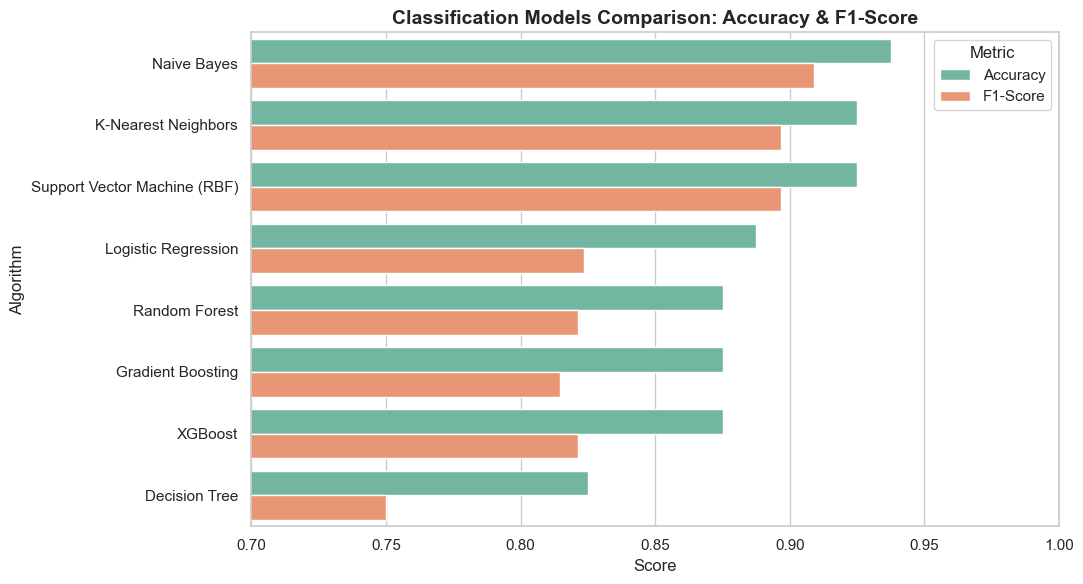

In [6]:
# Accuracy & F1-Score Comparison Bar Chart
fig, ax = plt.subplots(figsize=(11, 6))
df_plot = results_df.melt(id_vars="Algorithm", value_vars=["Accuracy", "F1-Score"], var_name="Metric", value_name="Score")

sns.barplot(data=df_plot, x="Score", y="Algorithm", hue="Metric", palette="Set2", ax=ax)
plt.title("Classification Models Comparison: Accuracy & F1-Score", fontsize=14, fontweight='bold')
plt.xlabel("Score")
plt.xlim(0.70, 1.0)
plt.tight_layout()
plt.show()

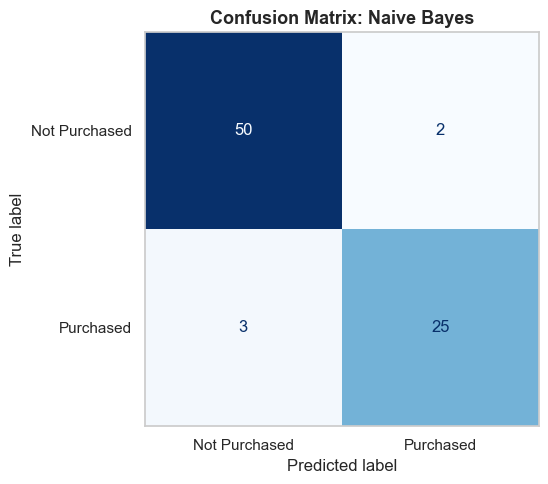

In [7]:
# Confusion Matrix for Best Model (Naive Bayes)
best_model_name = results_df.iloc[0]['Algorithm']
cm = confusion_matrix(y_test, predictions[best_model_name])

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not Purchased", "Purchased"]).plot(
    cmap='Blues', ax=ax, colorbar=False
)
plt.title(f"Confusion Matrix: {best_model_name}", fontsize=13, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

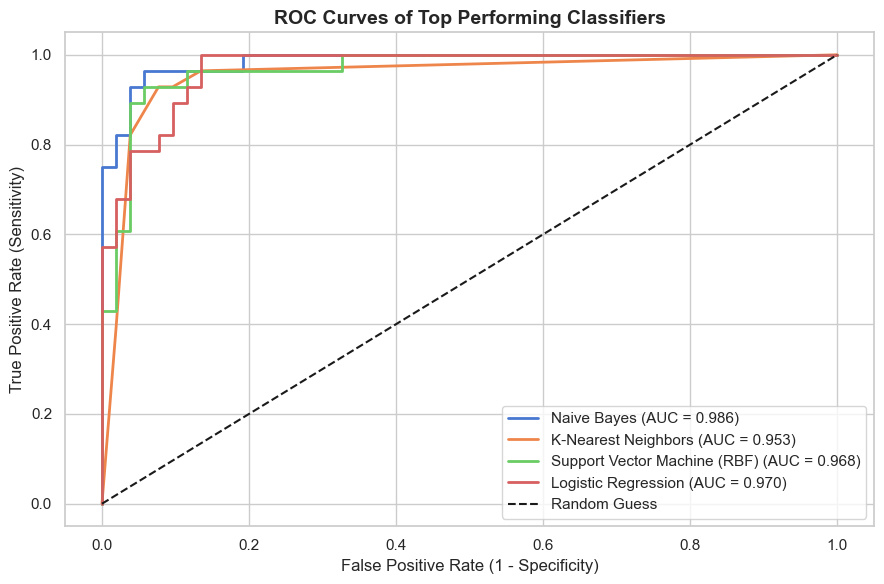

In [8]:
# ROC Curves for Top Performing Models
plt.figure(figsize=(9, 6))
top_models = results_df['Algorithm'].head(4).tolist()

for name in top_models:
    if probabilities[name] is not None:
        fpr, tpr, _ = roc_curve(y_test, probabilities[name])
        auc_val = roc_auc_score(y_test, probabilities[name])
        plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})", lw=2)

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label="Random Guess")
plt.title("ROC Curves of Top Performing Classifiers", fontsize=14, fontweight='bold')
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 6. Key Takeaways & Conclusion
- **Top Performer**: **Naive Bayes (GaussianNB)** achieved the highest test accuracy of **93.75%**, an F1-Score of **0.9091**, and an outstanding ROC-AUC of **0.9856**.
- **K-Nearest Neighbors** and **SVM (RBF)** tied closely in 2nd place with **92.50%** accuracy and **0.8966** F1-score.
- Feature standardization was vital for distance-based models (KNN and SVM) to perform at their peak.
